# Tree next to chr

If you have a newick tree you might want to add it alongside your synteny plots. For that we tried to implement simple newick visualisation alongside synteny tracks (I just got tired from drawing trees in affinity). 

The principle is super simple where we use same y for the tip of tree and chr, so they line up, for processing newick we are suing Bio. 

In [33]:
import sys
sys.path.insert(0, "..")

from Bio import Phylo
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import Image, display
from functions import plot

%matplotlib inline

## 1. opening the tree

Lets say we have `((spA,spB),spC);`. So spA and spB are closer and spC is basal. `Phylo.read()` reads the newick and then we can even revise it with `Phylo.draw_ascii()`.

In [34]:
tree = Phylo.read("../example_data/species_demo.nwk", "newick")
Phylo.draw_ascii(tree)

                                       ____________________________________ spA
  ____________________________________|
_|                                    |____________________________________ spB
 |
 |____________________________________ spC



## 2. get the names

Tips are the ends of the tree. We take their names and call them a, b and c here.

In [35]:
tips = tree.get_terminals()
a = tips[0].name
b = tips[1].name
c = tips[2].name
print(a, b, c)

spA spB spC


## 3. Where to put names

Lets put A at y = 0, B at -1.5 and C at -2.5 etc. A and B join in the middle, hence (0 + -1.5) / 2 = -0.75. We call that yab.

In [36]:
ya = 0
yb = -1.5
yc = -2.5

yab = (ya + yb) / 2
print(yab)

-0.75


## 4. draw
The tree is made of six lines. Here I'm trying to draw it one by one. 
`ax.plot([x1, x2], [y1, y2])` connects two points: `(x1, y1)` and `(x2, y2)`. First list gives x positions, second gives y positions.

We keep the same figure. `display(fig)` shows it again after adding the next line. To start over, run section 4 from beginning.

A is at ya = 0 and B is at yb = -1.5.

Lets draw from `(1, 0)` to `(1, -1.5)`. Both x values are 1, so the line is vertical. In code we use ya and yb for those two y values.

We will keep axis visible for now (we hide it before) so we can see the coordinates.

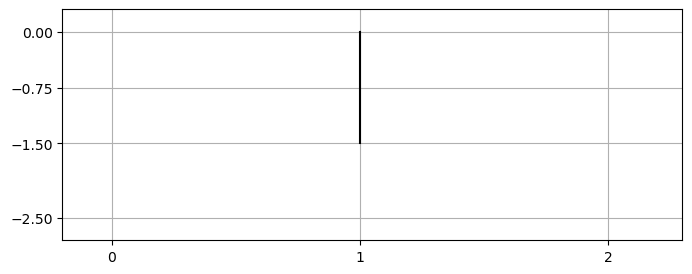

In [37]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.set_xlim(-0.2, 2.3)
ax.set_ylim(-2.8, 0.3)
ax.set_xticks([0, 1, 2])
ax.set_yticks([ya, yab, yb, yc])
ax.grid(True)

ax.plot([1, 1], [ya, yb], color="black")
plt.show()

Now draw from `(1, 0)` to `(2, 0)`. Both y values are ya = 0, -> horizontal line. It starts at the top of our vertical line and ends at A's tip.

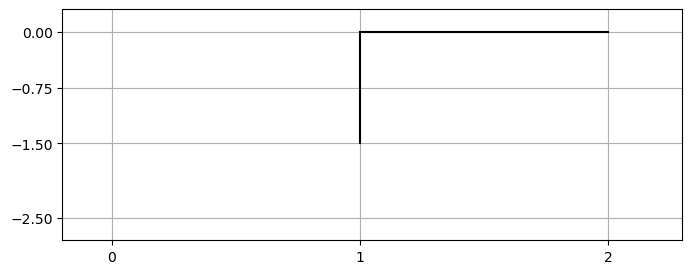

In [38]:
ax.plot([1, 2], [ya, ya], color="black")
display(fig)

Same thing at yb = -1.5: from `(1, -1.5)` to `(2, -1.5)`.

Now we have the A/B. Their tips both end at x = 2.

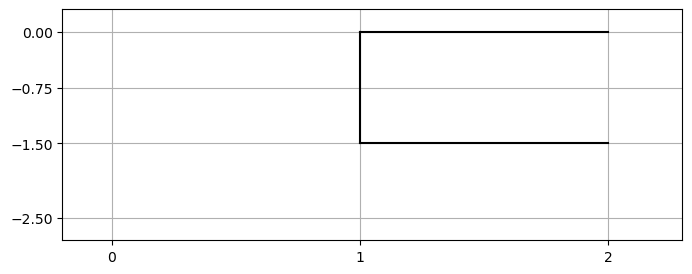

In [39]:
ax.plot([1, 2], [yb, yb], color="black")
display(fig)

connect middle of A/B to the left:

Earlier we calculated yab = -0.75. This is half between ya and yb, so it sits in the middle of our vertical line.

Draw from `(0, -0.75)` to `(1, -0.75)`. y stays at yab; x go from 0 to 1.

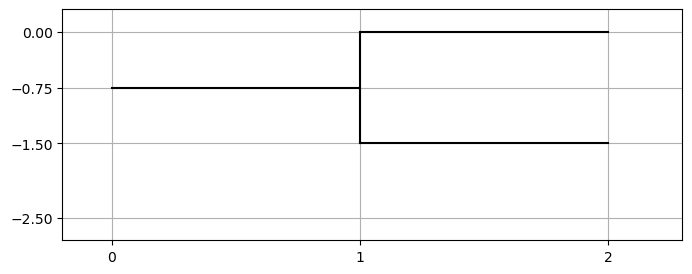

In [40]:
ax.plot([0, 1], [yab, yab], color="black")
display(fig)

Now it goes to C:

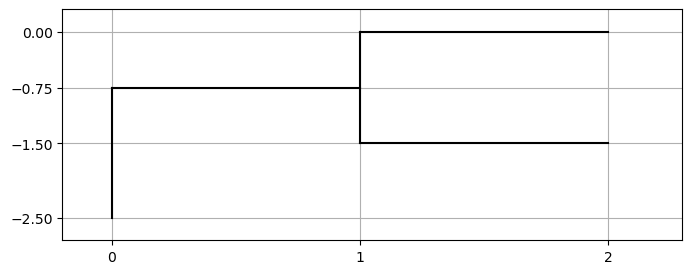

In [41]:
ax.plot([0, 0], [yab, yc], color="black")
display(fig)

Add branch to C:

C is at yc = -2.5. Draw from `(0, -2.5)` to `(2, -2.5)`.
its tip still ends at x = 2. The tree is now complete.

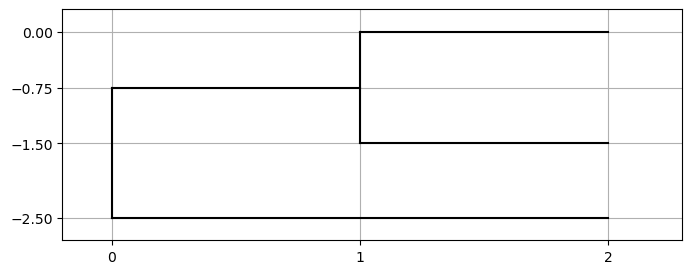

In [42]:
ax.plot([0, 2], [yc, yc], color="black")
display(fig)

### Add chrA

Now lets put chr, for that we need room on the right. 

`Rectangle((x, y), width, height)` takes the bottom-left corner. We want the bar centred at ya = 0. Its height is 0.08, so the bottom is ya - 0.04.

It starts at x = 2.8 and has width 3, hence it ends at 5.8. 
A tip and the middle of this bar both have y = ya. 

They line up

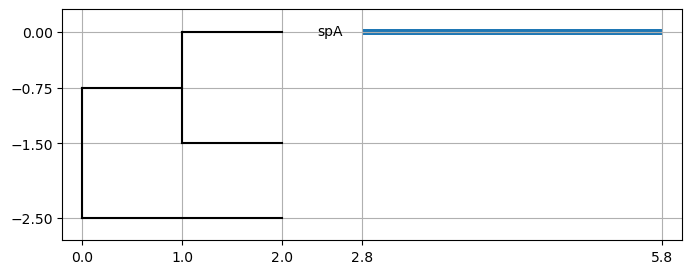

In [43]:
ax.set_xlim(-0.2, 6)
ax.set_xticks([0, 1, 2, 2.8, 5.8])
ax.add_patch(Rectangle((2.8, ya - 0.04), 3, 0.08))
ax.text(2.6, ya, a, ha="right", va="center")
display(fig)

### Add chrB
In the same way we add ChrB
We use yb this time. Its bottom is -1.5 - 0.04 = -1.54, so the bar centre stays at -1.5, level with B tip.

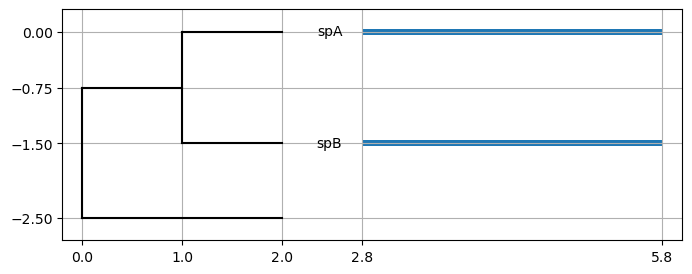

In [44]:
ax.add_patch(Rectangle((2.8, yb - 0.04), 3, 0.08))
ax.text(2.6, yb, b, ha="right", va="center")
display(fig)

### Add chrC

Same again with yc. 

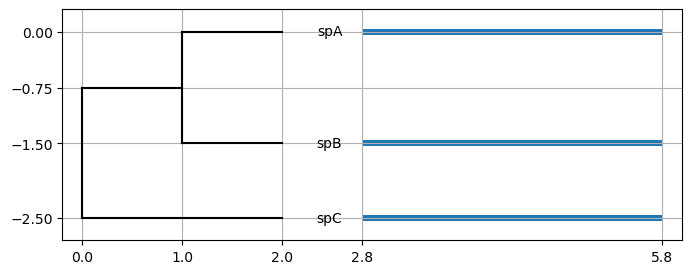

In [45]:
ax.add_patch(Rectangle((2.8, yc - 0.04), 3, 0.08 ))
ax.text(2.6, yc, c, ha="right", va="center")
display(fig)

Now once we've seen how it works I hide axes 

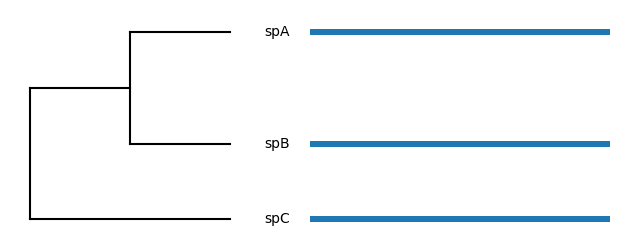

In [50]:
ax.axis("off")
display(fig)

## 5. What if chain does not fit the tree?

I imagened this situation where user might input chain in one oreder but phylogeny and tree goes in another, so we need some error message, for now its implemented as following: 

In [47]:
chain = ["spA", "spC", "spB"]
i = chain.index(a)
j = chain.index(b)
print(i, j)

if abs(i - j) != 1:
    print("A and B are separated in chain.")

0 2
A and B are separated in chain.


## 6. Final function

Above we picked y by hand. SynSlug takes it from the chr row positions it already calculated, including space for extra tracks.


This is the same `draw_tree()` used in functions.py. It repeats the drawing for all groups in the tree. the main difference is that I added some error handling. 

(`node.clades` means the children of a node.)

In [ ]:
def draw_tree(ax, cfg, lay):
    from Bio import Phylo

    tree = Phylo.read(cfg["tree"], "newick")
    chain = cfg["chain"]
    tips = tree.get_terminals()
    names = []
    for tip in tips:
        names.append(tip.name)
    if None in names or len(names) != len(set(names)):
        raise ValueError("tree tips need unique species names")
    missing = []
    for sp in chain:
        if sp not in names:
            missing.append(sp)
    if missing:
        raise ValueError(f"tree is missing species from chain: {missing}")
    for tip in tips:
        if tip.name not in chain:
            tree.prune(tip)

    y = {}
    for tip in tree.get_terminals():
        y[tip] = lay["track"][tip.name]["y"]

    for node in tree.get_nonterminals(order="postorder"):
        rows = []
        for tip in node.get_terminals():
            rows.append(chain.index(tip.name))
        # Every group must occupy consecutive rows in chain.
        if max(rows) - min(rows) + 1 != len(rows):
            raise ValueError("tree groups non-adjacent species; reorder chain so each clade stays together")
        ys = []
        for child in node.clades:
            ys.append(y[child])
        y[node] = (min(ys) + max(ys)) / 2

    tree.root.branch_length = 0
    depth = tree.depths(unit_branch_lengths=True)
    d = max(depth.values()) or 1
    x = {}
    for node in tree.find_clades():
        x[node] = depth[node] / d
        if node.is_terminal():
            x[node] = 1

    ax.plot([0, x[tree.root]], [y[tree.root], y[tree.root]], color="black", lw=1)
    for node in tree.get_nonterminals():
        ys = []
        for child in node.clades:
            ys.append(y[child])
        ax.plot([x[node], x[node]], [min(ys), max(ys)], color="black", lw=1)
        for child in node.clades:
            ax.plot([x[node], x[child]], [y[child], y[child]], color="black", lw=1)
    ax.set_xlim(-0.05, 1.05)
    ax.axis("off")

Now just to show how it looks all together also with our loops and bedgraph inputs

== tree.toml ==
  spA-spB: 280 links
  spB-spC: 310 links
  auto-generated 4 focal colours
  saved examples/plot_tree.png
  saved examples/plot_tree.svg


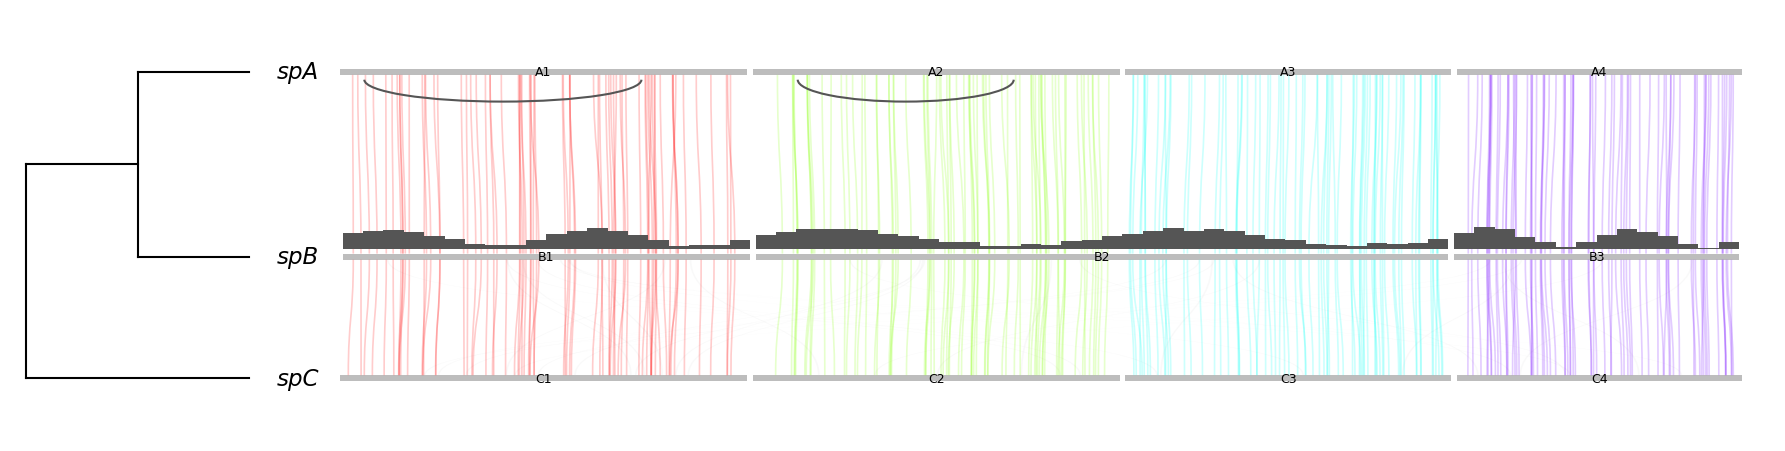

In [48]:
plot("../examples/tree.toml")
display(Image("../examples/plot_tree.png"))